In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib_fontja

In [2]:
N_CONDITIONS = {"FD001": 1, "FD002": 6, "FD003": 1, "FD004": 6}
DATASETS = list(N_CONDITIONS)

In [3]:
# データ読み込み
dfs = {}
for i, name in enumerate(DATASETS):
    df_tmp = pd.read_csv(f'../data/CMAPSSData/train_{name}.txt', sep=r"\s+", header=None)
    # カラム名をエンジンID(ユニット)、サイクル、運転設定(1~3)、センサー(1~21)に指定
    df_tmp.columns = ["エンジンID", "サイクル", *[f"op{i}" for i in range(1, 4)], *[f"s{i}" for i in range(1, 22)]]
    dfs[name] = df_tmp

In [4]:
# 運転条件の組み合わせを条件番号に変換
settings = ["op1", "op2", "op3"]

for name in N_CONDITIONS.keys():
    key = dfs[name][["op1", "op2", "op3"]].round({"op1": 0, "op2": 2, "op3": 0})
    dfs[name]["condition"] = key.apply(tuple, axis=1).map(
        {k: i for i, k in enumerate(sorted(key.drop_duplicates().apply(tuple, axis=1)))}
    )
    print("各条件の setting 平均値:")
    print(dfs[name].groupby("condition")[settings].mean().round(2))
    print("各条件の行数:")
    print(dfs[name]["condition"].value_counts().sort_index())

各条件の setting 平均値:
           op1  op2    op3
condition                 
0         -0.0  0.0  100.0
各条件の行数:
condition
0    20631
Name: count, dtype: int64
各条件の setting 平均値:
            op1   op2    op3
condition                   
0           0.0  0.00  100.0
1          10.0  0.25  100.0
2          20.0  0.70  100.0
3          25.0  0.62   60.0
4          35.0  0.84  100.0
5          42.0  0.84  100.0
各条件の行数:
condition
0     8044
1     8096
2     8122
3     8002
4     8037
5    13458
Name: count, dtype: int64
各条件の setting 平均値:
           op1  op2    op3
condition                 
0         -0.0  0.0  100.0
各条件の行数:
condition
0    24720
Name: count, dtype: int64
各条件の setting 平均値:
            op1   op2    op3
condition                   
0           0.0  0.00  100.0
1          10.0  0.25  100.0
2          20.0  0.70  100.0
3          25.0  0.62   60.0
4          35.0  0.84  100.0
5          42.0  0.84  100.0
各条件の行数:
condition
0     9238
1     9224
2     9091
3     9139
4     9162
5    1539

In [5]:
# 各エンジンユニットにおける最大サイクル(寿命)を取得
lifes = {}
for name in DATASETS:
    life_tmp = dfs[name].groupby('エンジンID')['サイクル'].max()
    lifes[name] = life_tmp

## エンジンごとの寿命分布確認

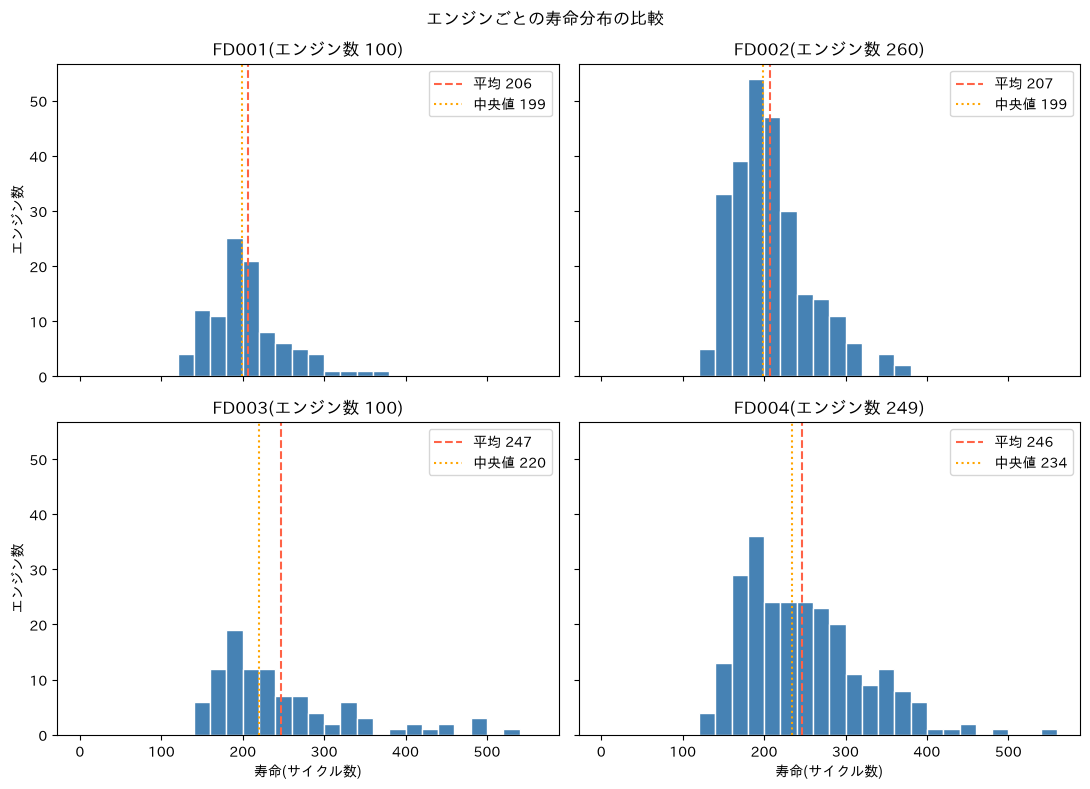

In [6]:
# 各エンジンユニットの寿命分布を比較するヒストグラムを作成
all_values = pd.concat(lifes.values())
bins = np.arange(0, all_values.max() + 20, 20)
 
fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharex=True, sharey=True)
 
for i, ax in enumerate(axes.flat):
    life = lifes[list(lifes.keys())[i]]
    ax.hist(life, bins=bins, color="steelblue", edgecolor="white")
    ax.axvline(life.mean(), color="tomato", linestyle="--", label=f"平均 {life.mean():.0f}")
    ax.axvline(life.median(), color="orange", linestyle=":", label=f"中央値 {life.median():.0f}")
    ax.set_title(f"FD00{i+1}(エンジン数 {len(life)})")
    ax.legend()
 
for ax in axes[1]:
    ax.set_xlabel("寿命(サイクル数)")
for ax in axes[:, 0]:
    ax.set_ylabel("エンジン数")
 
fig.suptitle("エンジンごとの寿命分布の比較")
fig.tight_layout()
plt.show()

## 不要なセンサー除外

In [7]:
# センサーの選択用関数の定義
sensor_cols = [f"s{i}" for i in range(1, 22)]
STD_THRESHOLD = 1e-4

def select_sensors(df, threshold=STD_THRESHOLD):
    """運転条件内の標準偏差の最小値が閾値を超えるセンサーを残す。

    単一条件のデータセットでは、全体の標準偏差で判定するのと同じ結果になる。
    戻り値: (残すセンサーのリスト, 判定根拠の表)
    """
    by_cond = df.groupby("condition")[sensor_cols]
    min_std = by_cond.std().min()
    summary = pd.DataFrame({
        "条件内std(最小)": min_std,
        "条件内ユニーク数(最小)": by_cond.nunique().min(),
        "採用": min_std > threshold,
    })
    keep = summary.index[summary["採用"]].tolist()
    return keep

In [8]:
# センサーの選択
dfs_new = {}
sensors = {}

# 標準偏差が閾値を超えているセンサーを残し、閾値以下のものは値の変動がほぼないとみなし除外する
for name, df in dfs.items():
    stds = df[sensor_cols].std()
    sensor_id = select_sensors(df)
    sensors[name] = sensor_id
    df = df[['エンジンID', 'サイクル', *[f'op{j}' for j in range(1, 4)]]+sensors[name]]
    dfs_new[name] = df
    print(f"{name}_除外したセンサー:", [s for s in sensor_cols if s not in sensors[name]])
    print(f"{name}_残ったセンサー:", sensors[name])

FD001_除外したセンサー: ['s1', 's5', 's10', 's16', 's18', 's19']
FD001_残ったセンサー: ['s2', 's3', 's4', 's6', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']
FD002_除外したセンサー: ['s1', 's5', 's10', 's16', 's18', 's19']
FD002_残ったセンサー: ['s2', 's3', 's4', 's6', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']
FD003_除外したセンサー: ['s1', 's5', 's16', 's18', 's19']
FD003_残ったセンサー: ['s2', 's3', 's4', 's6', 's7', 's8', 's9', 's10', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']
FD004_除外したセンサー: ['s1', 's5', 's16', 's18', 's19']
FD004_残ったセンサー: ['s2', 's3', 's4', 's6', 's7', 's8', 's9', 's10', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']


## プロットに使用するエンジンユニットの選択

In [9]:
ENGINES = {}
subs_raw = {}

# 各データセットで寿命が最も短いユニット、寿命中央値のユニット、寿命が最も長いユニットを選択
for name, life in lifes.items():
    sorted_life = life.sort_values()
    ENGINES[name] = [sorted_life.index[0], sorted_life.index[len(sorted_life) // 2], sorted_life.index[-1]]
    tmp = dfs_new[name]
    sub = tmp[tmp["エンジンID"].isin(ENGINES[name])].copy()
    subs_raw[name] = sub
    print(f"{name}_選んだエンジン(寿命):", {u: int(life[u]) for u in ENGINES[name]})

FD001_選んだエンジン(寿命): {np.int64(39): 128, np.int64(68): 199, np.int64(69): 362}
FD002_選んだエンジン(寿命): {np.int64(244): 128, np.int64(9): 199, np.int64(112): 378}
FD003_選んだエンジン(寿命): {np.int64(99): 145, np.int64(78): 221, np.int64(55): 525}
FD004_選んだエンジン(寿命): {np.int64(214): 128, np.int64(147): 234, np.int64(118): 543}


## データ可視化

In [10]:
def plot_sensor_trends(df, name, sensors, engines, life, window=10, align_end=True):
    df = df.copy()
    print(f'{name} センサー推移(薄線: 生データ / 濃線: {window}サイクル移動平均)')
    #  横軸:サイクル数 or 故障までの残りサイクル(RUL)
    if align_end:
        df["x"] = df["サイクル"] - df["エンジンID"].map(life)  # 故障時点が 0、それ以前は負の値
        xlabel = "故障までのサイクル(0 = 故障)"
    else:
        df["x"] = df["サイクル"]
        xlabel = "サイクル"
    
    # ===== 移動平均(エンジンごとに計算する点が重要) =====
    for s in sensors:
        df[f"{s}_ma"] = df.groupby("エンジンID")[s].transform(
            lambda x: x.rolling(window, min_periods=1).mean()
        )
    
    # ===== プロット =====
    n_cols = 4
    n_rows = int(np.ceil(len(sensors) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3 * n_rows), sharex=True)
    colors = plt.cm.tab10.colors
    
    for ax, s in zip(axes.flat, sensors):
        for i, id in enumerate(engines):
            tmp = df
            e = tmp[tmp["エンジンID"] == id]
            c = colors[i % 10]
            ax.plot(e["x"], e[s], color=c, alpha=0.25, linewidth=0.8)  # 生データ(薄く)
            ax.plot(e["x"], e[f"{s}_ma"], color=c, linewidth=1.8,
                    label=f"エンジンID {id}(寿命 {life[id]})")         # 移動平均(濃く)
        ax.set_title(s)
    
    # 余ったサブプロットを消す
    for ax in axes.flat[len(sensors):]:
        ax.axis("off")
    
    for ax in axes[-1]:
        ax.set_xlabel(xlabel)
    
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper right")
    fig.suptitle(f"{name} センサー推移(薄線: 生データ / 濃線: {window}サイクル移動平均)")
    fig.tight_layout(rect=[0, 0, 0.88, 0.96])
    plt.show()

FD001 センサー推移(薄線: 生データ / 濃線: 10サイクル移動平均)


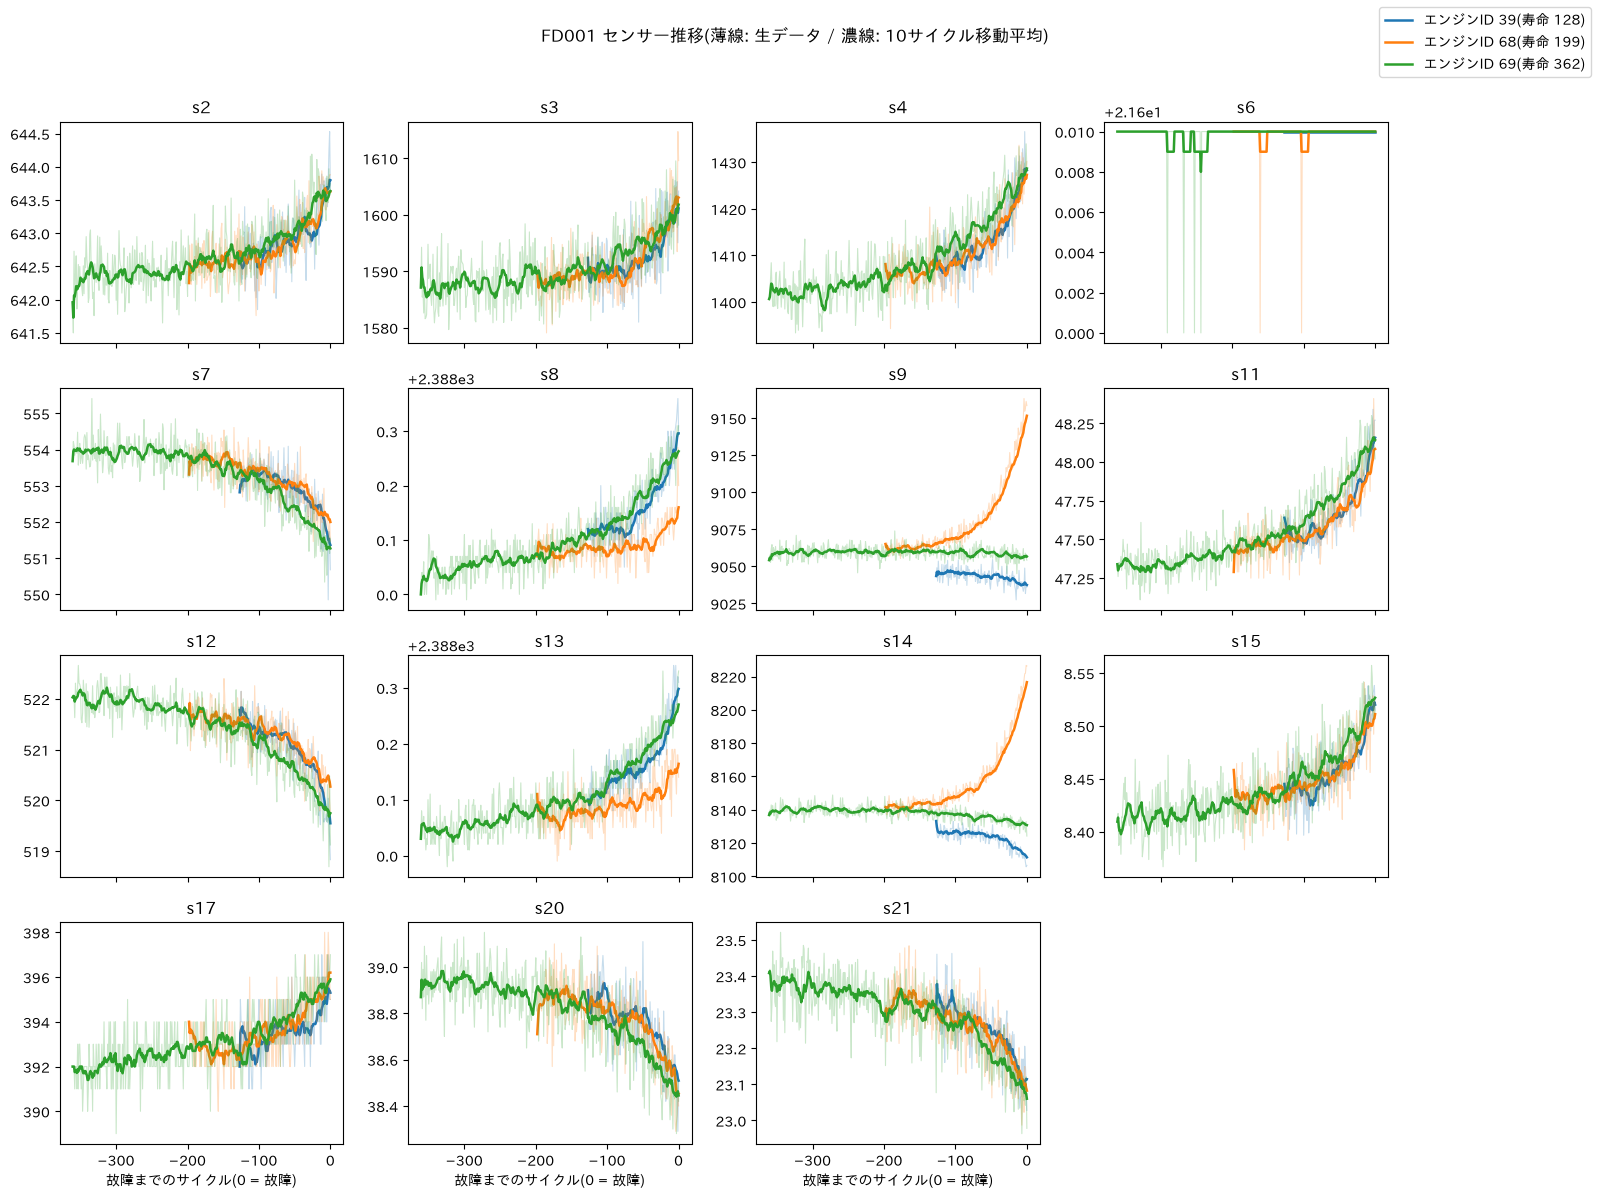

FD002 センサー推移(薄線: 生データ / 濃線: 10サイクル移動平均)


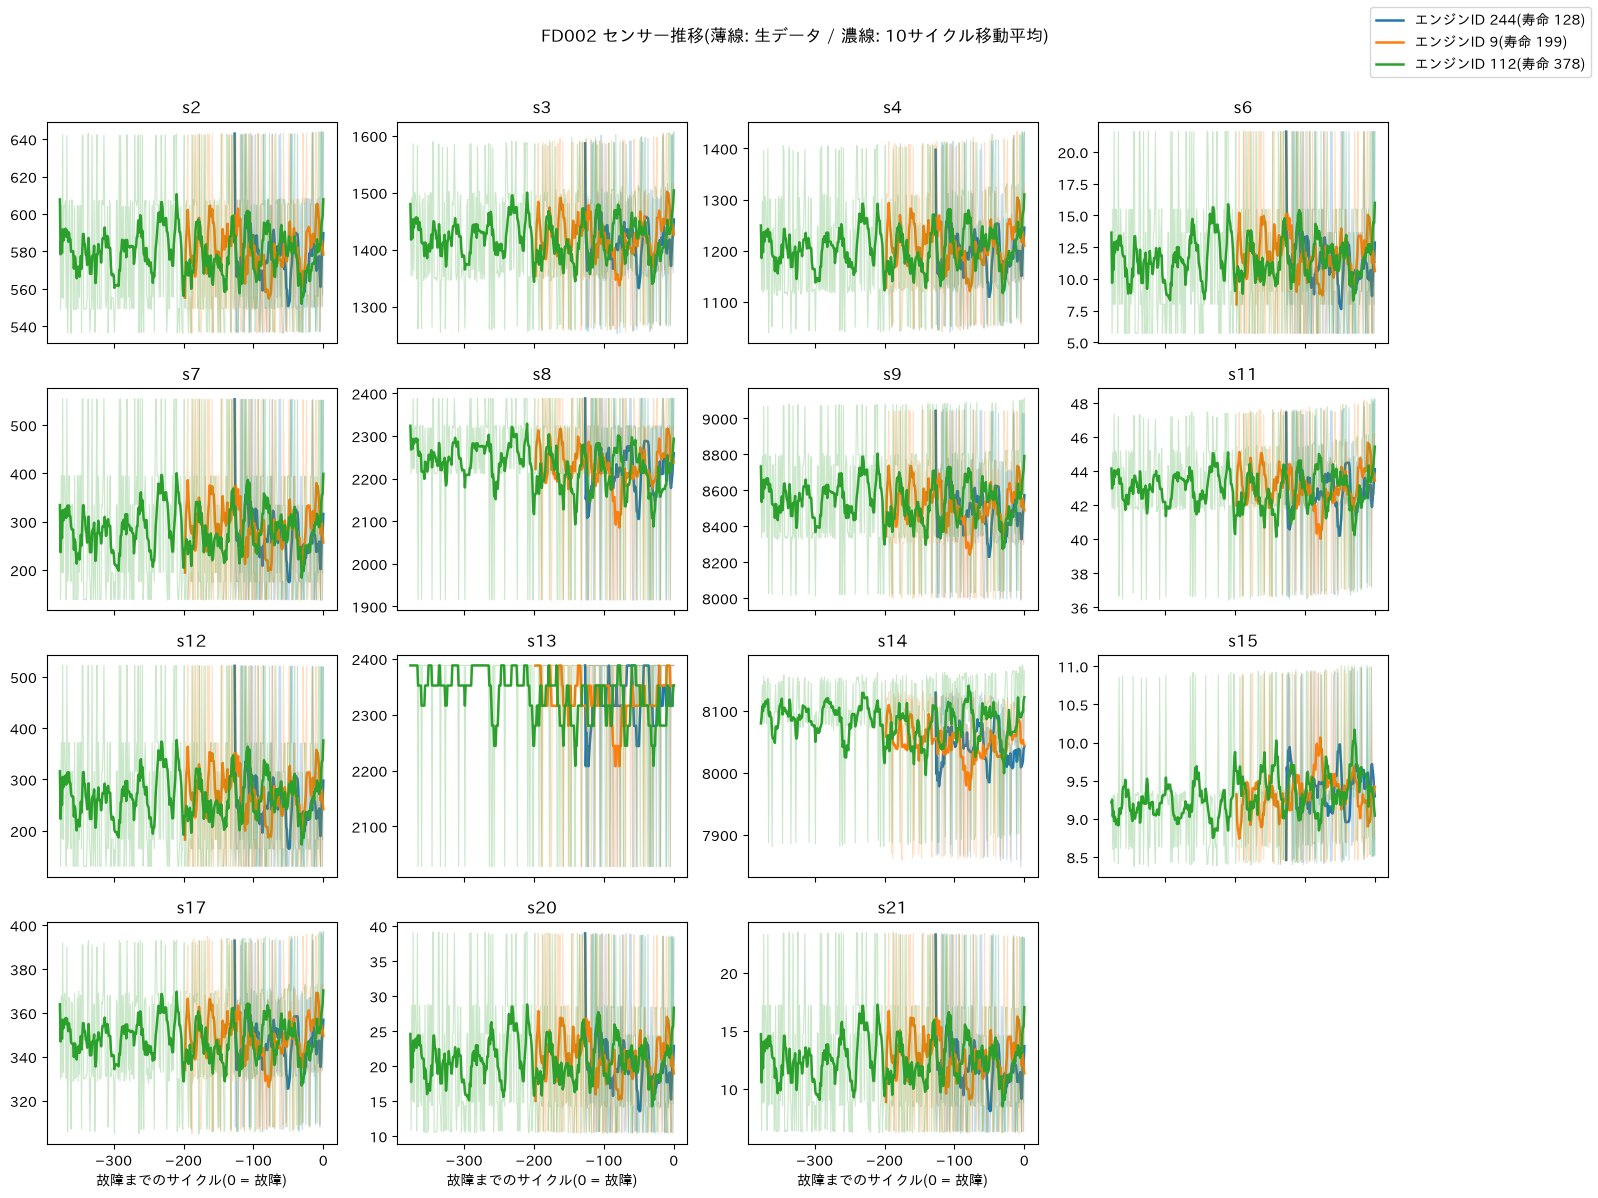

FD003 センサー推移(薄線: 生データ / 濃線: 10サイクル移動平均)


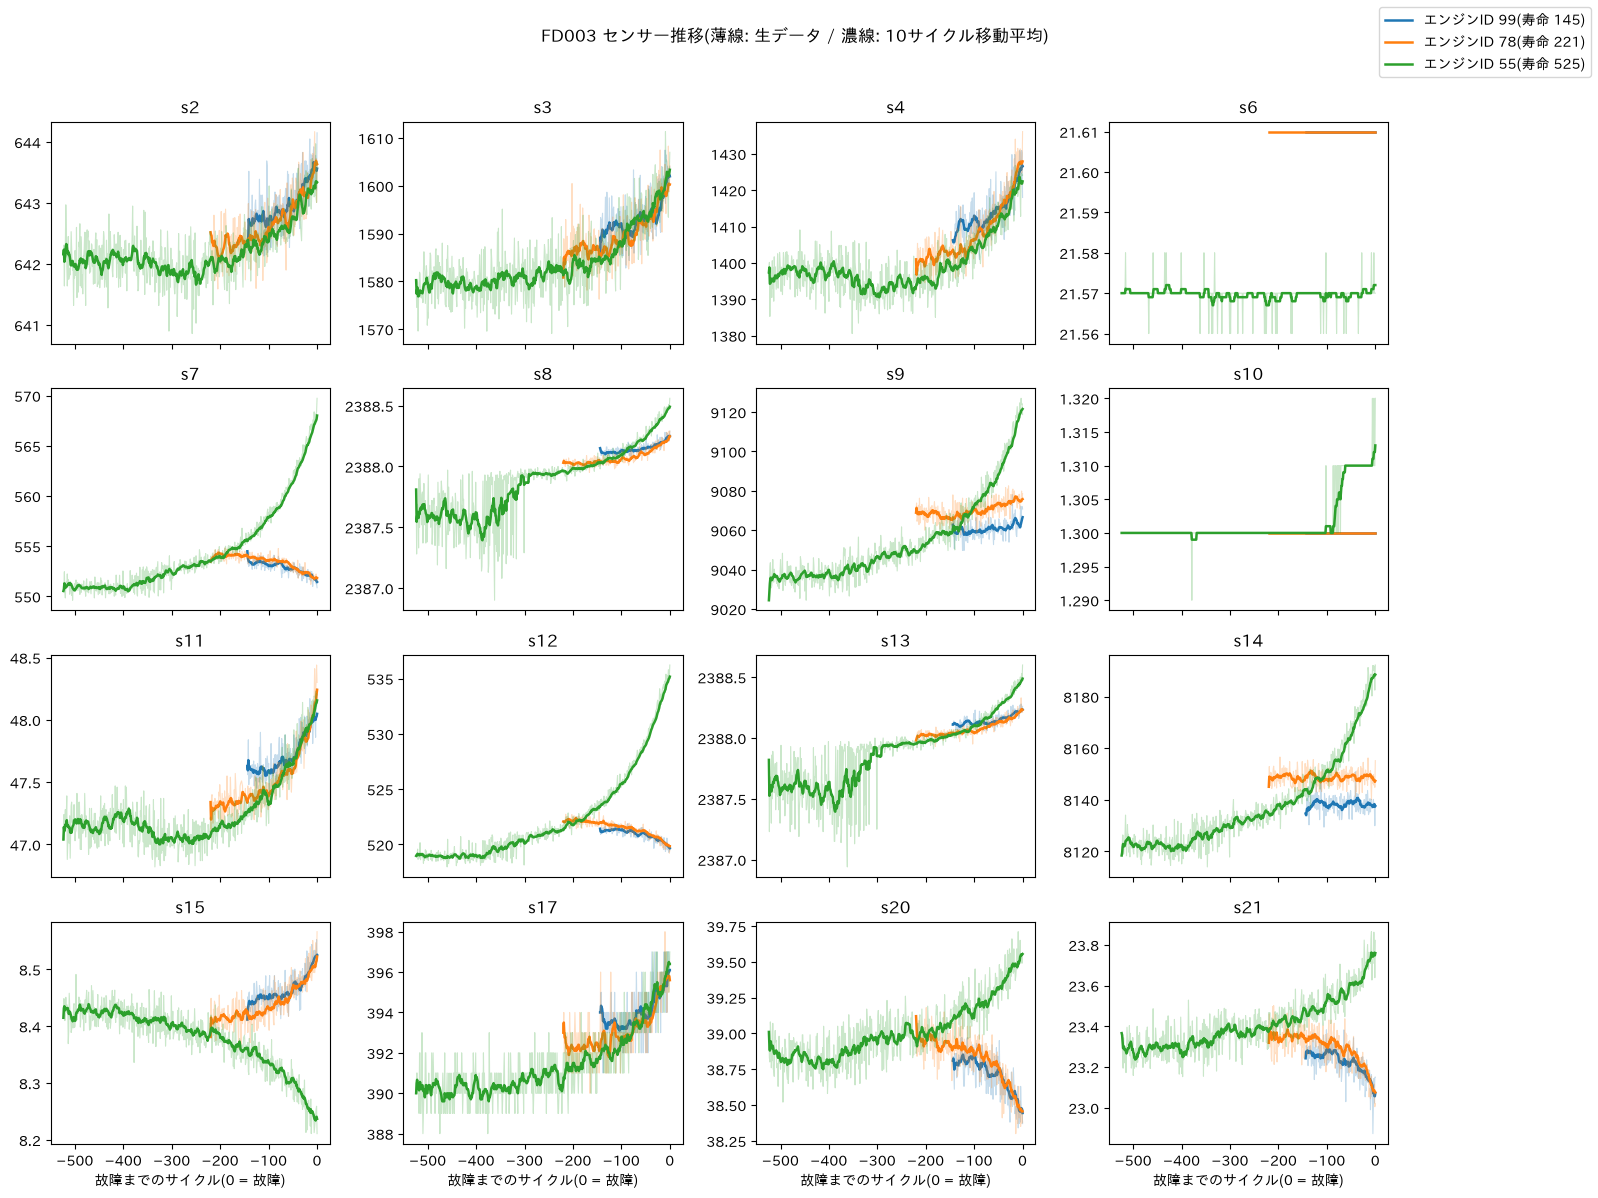

FD004 センサー推移(薄線: 生データ / 濃線: 10サイクル移動平均)


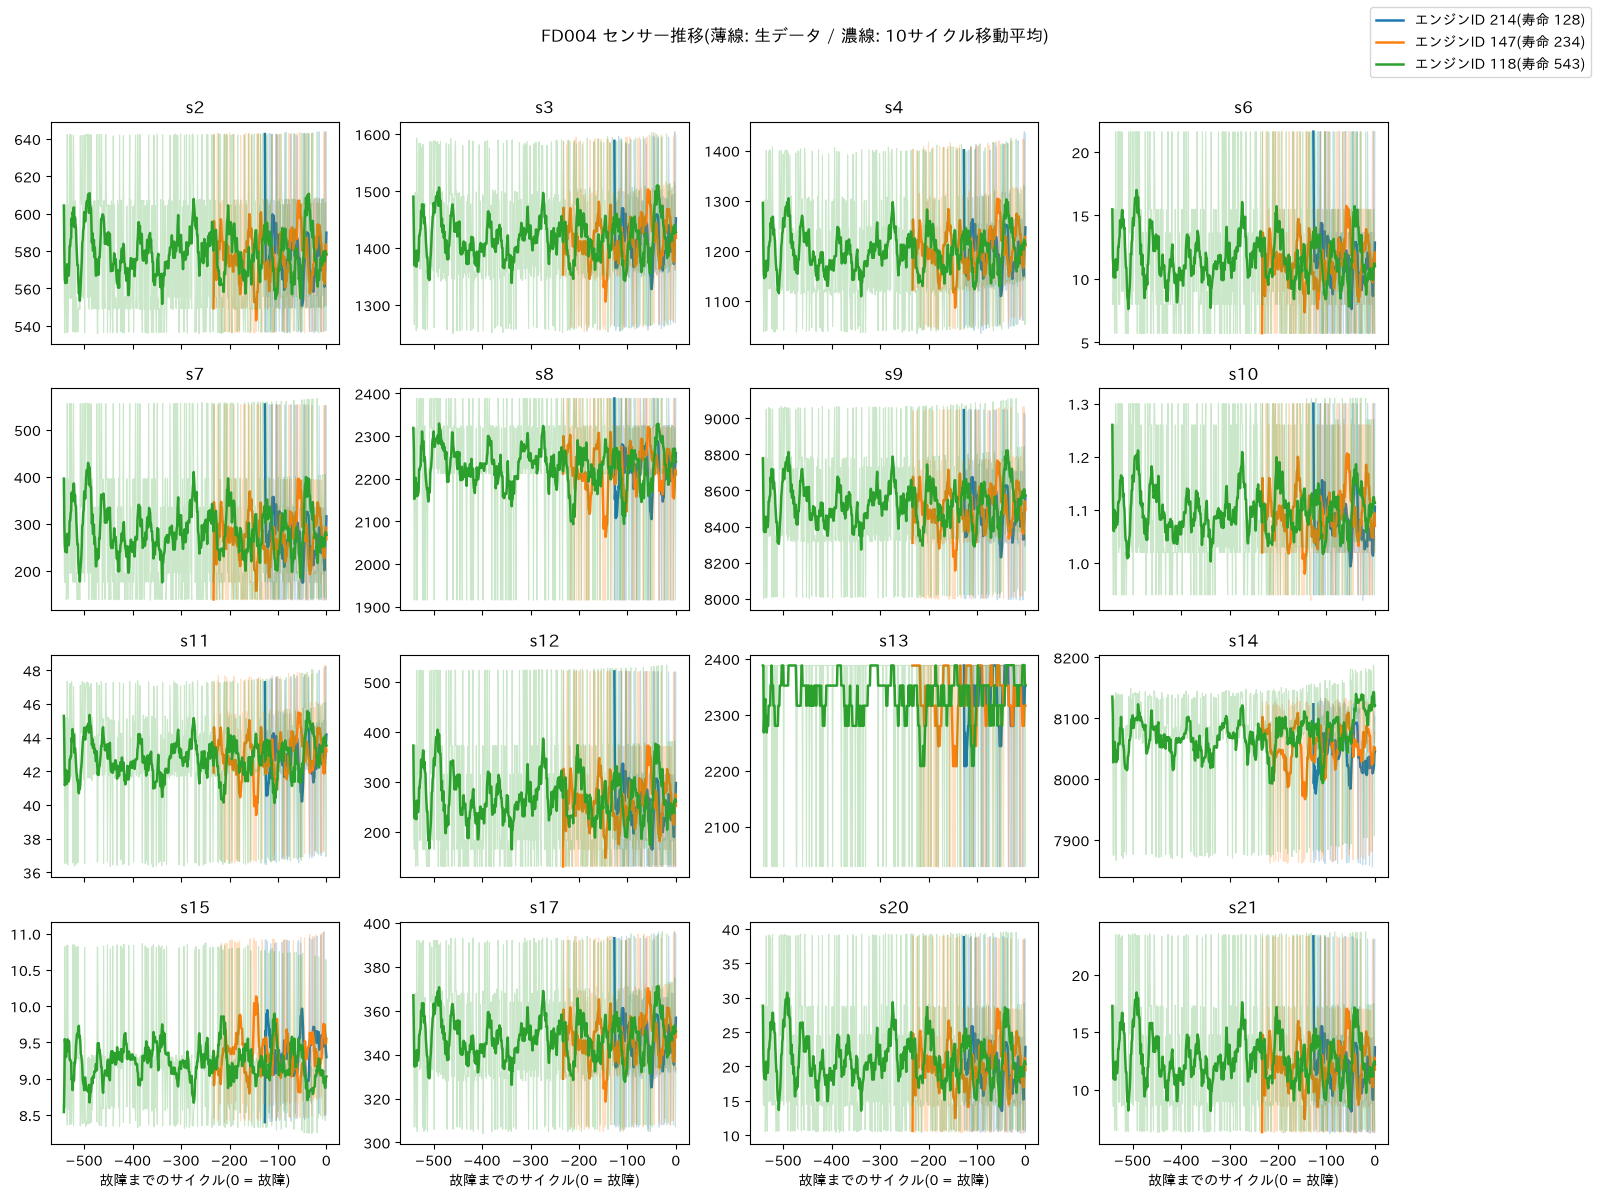

In [11]:
for name in DATASETS:
    plot_sensor_trends(subs_raw[name], name, sensors[name], ENGINES[name], lifes[name])

## FD002、FD004について運転条件ごとに標準化

In [12]:
# 標準化用関数定義
def normalize_by_condition(data, stats, sensors):
    out = data.copy()
    for s in sensors:
        mean = data["condition"].map(stats[(s, "mean")])
        std = data["condition"].map(stats[(s, "std")])
        out[s] = (data[s] - mean) / std
    return out

In [13]:
dfs_norm = {}

# Normalize=Trueのときは、運転条件ごとに標準化を行い、標準偏差が閾値を超えているセンサーを残す
for name, df in dfs.items():
    if name == "FD002" or name == "FD004":
        NORMALIZE = True
    else:
        NORMALIZE = False

    if NORMALIZE:
        stats = df.groupby("condition")[sensor_cols].agg(["mean", "std"])
        df = normalize_by_condition(df, stats, sensors[name])
        df = df[['エンジンID', 'サイクル', *[f'op{j}' for j in range(1, 4)]]+sensors[name]]
        dfs_norm[name] = df

In [14]:
subs_norm = {}

# 各データセットで寿命が最も短いユニット、寿命中央値のユニット、寿命が最も長いユニットを選択
for name, df in dfs_norm.items():
    tmp = dfs_norm[name]
    sub = tmp[tmp["エンジンID"].isin(ENGINES[name])].copy()
    subs_norm[name] = sub

## 標準化後のデータ可視化

FD002 センサー推移(薄線: 生データ / 濃線: 10サイクル移動平均)


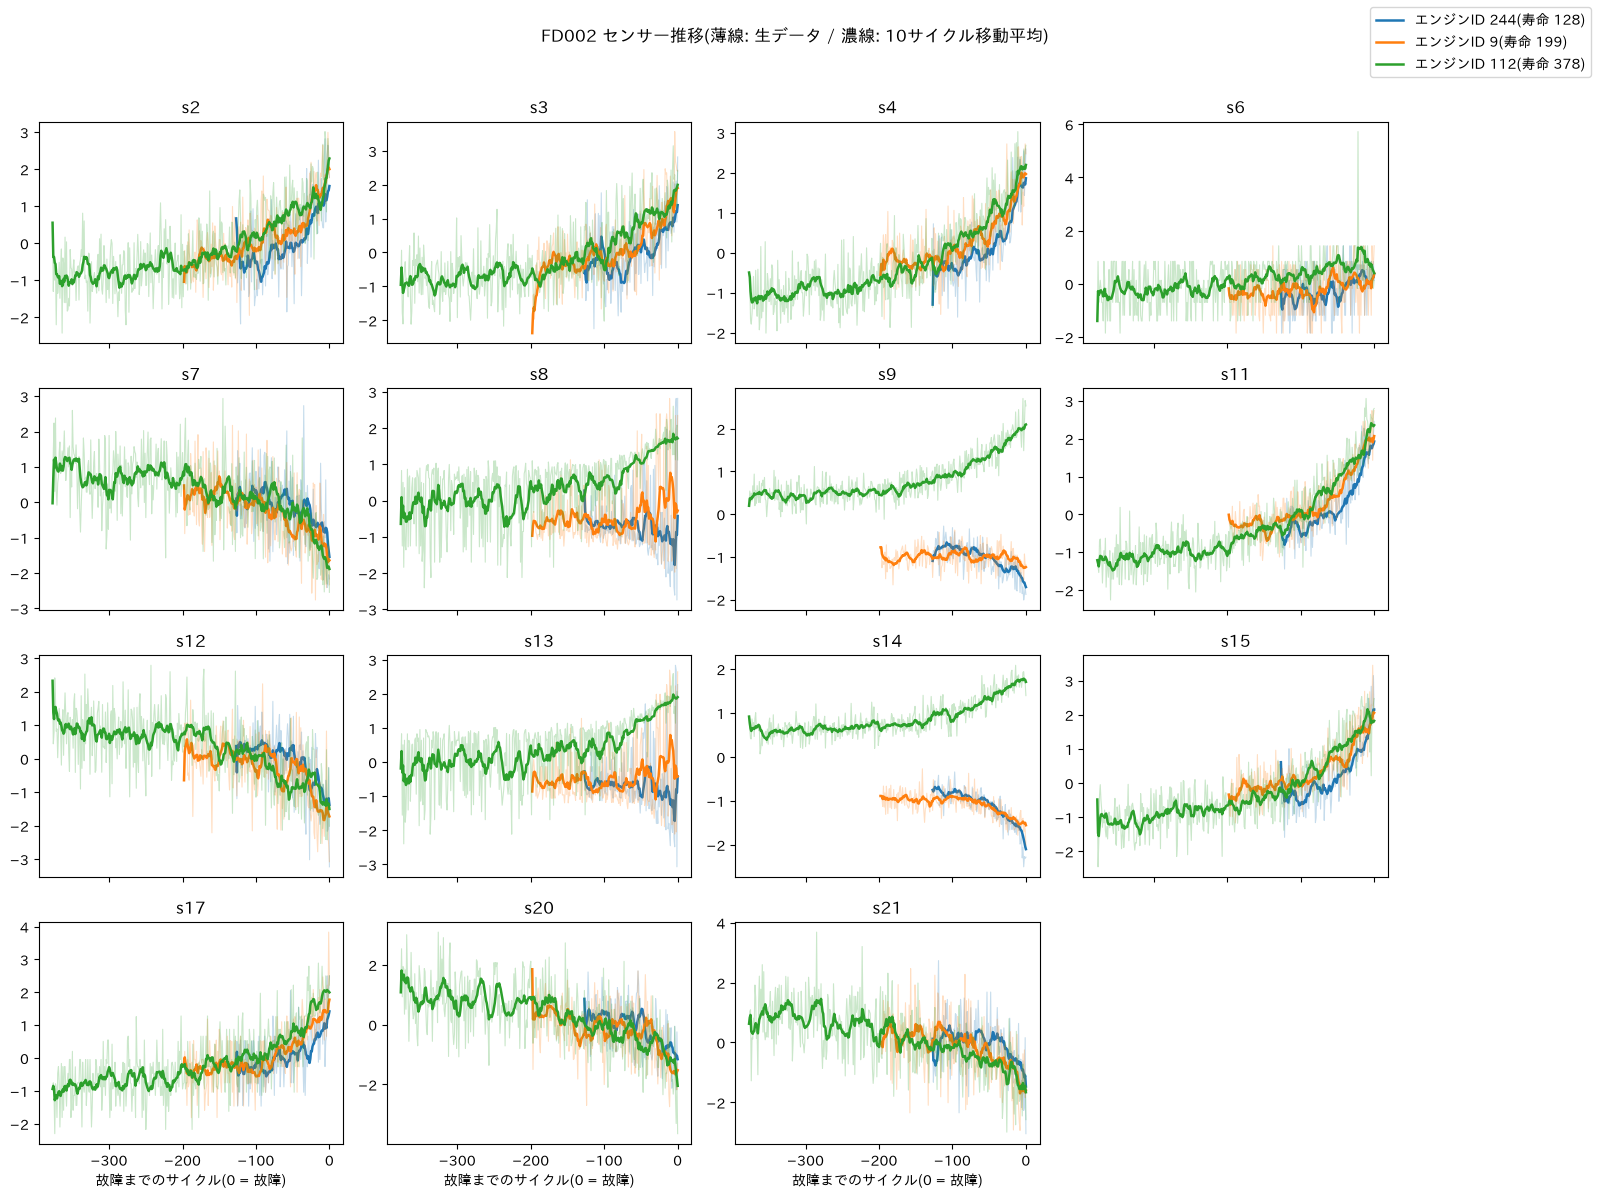

FD004 センサー推移(薄線: 生データ / 濃線: 10サイクル移動平均)


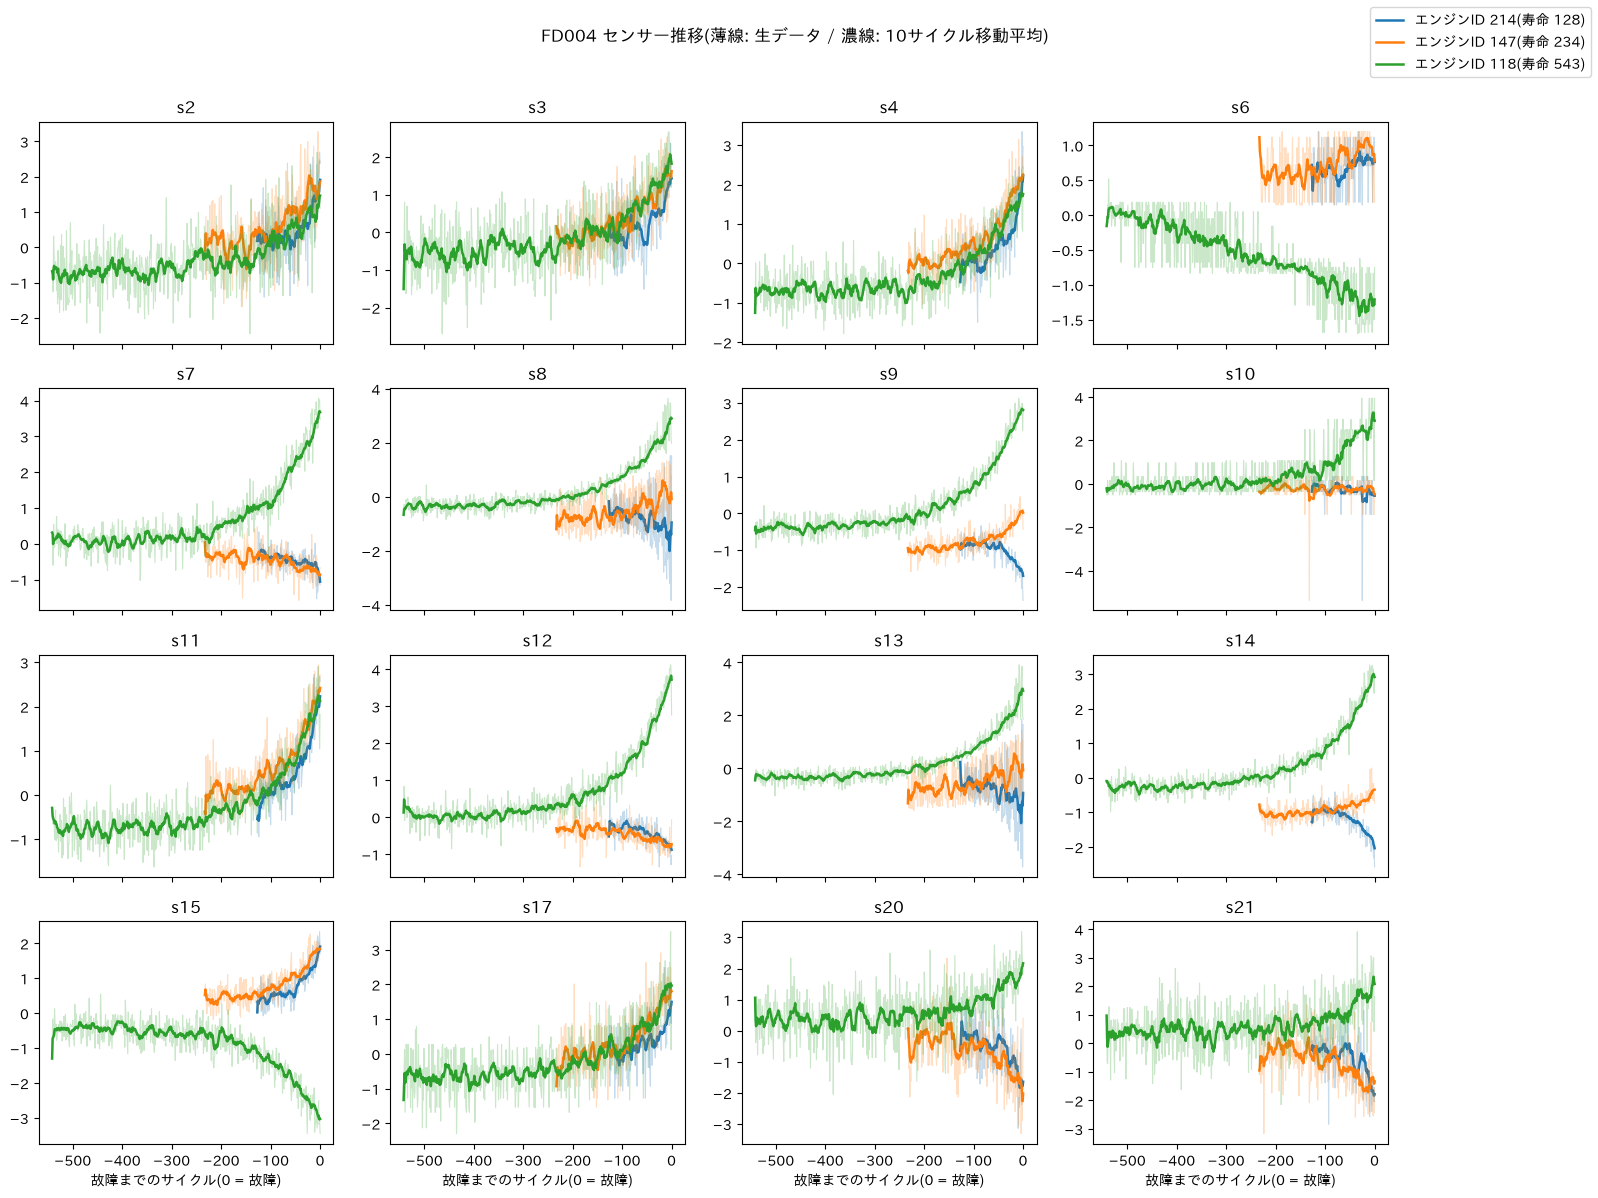

In [15]:
for name in DATASETS:
    if name == "FD002" or name == "FD004":
        plot_sensor_trends(subs_norm[name], name, sensors[name], ENGINES[name], lifes[name])